(replication-across-studies)=
# Replication across studies

Find the changes that replicate across studies with {api}`sumrank`, which ranks the
genes within each study and sums each gene's ranks across the studies, so that a gene
must rank high in study after study [@nakatsuka2025]. Most genes that one study finds
are not found by the others ([Why findings fail to
replicate](../statistics/aligning_studies.md#why-findings-fail-to-replicate)): some
changes are too small for the other studies to detect, and others belong to one study
alone. This page finds the genes that replicate in six cohorts with SumRank, checks how
well they predict the cases of a cohort left out, and then, under Choices, measures how
well the cohorts replicate each other: the genes found in k cohorts, π₁ between
cohorts, and combined p-values against the p-value that a change replicates.
[Replication](../statistics/replication.md) explains the statistics.

The cohorts are the six simulated ones of [Align and combine studies](combine_studies.ipynb),
aligned and analysed as there: {api}`analyse_each_study` tests each by
{api}`limma_voom` on its own, and the functions below take the {api}`StudyResults` it
returns. The simulation knows which monocyte genes the disease changes in every
cohort, and which genes one cohort alone changes.

In [1]:
import textwrap
import warnings

import matplotlib.pyplot as plt
import numpy as np

import cytepool
from cytepool import (
    CubeCollection,
    analyse_each_study,
    held_out_prediction,
    meta_analysis,
    read_cube,
    replication,
    sumrank,
)
from cytepool.plotting import (
    plot_held_out_auc,
    plot_replicated_genes,
    plot_study_agreement,
    plot_sumrank,
)
from cytepool.stats.combined_p_values import (
    combine_p_values,
    partial_conjunction,
)
from cytepool.stats.multiple_testing import adjust_p_values

cohorts = [f"cohort_{i}" for i in range(1, 7)]
cubes = {study: read_cube(f"simulated_{study}.cube.zarr") for study in cohorts}
cd4_subsets = {"CD4 naive": "CL:0000624", "CD4 memory": "CL:0000624"}
cell_types = {
    "CL:0000236": "B cells",
    "CL:0000624": "CD4 T cells",
    "CL:0000623": "NK cells",
    "CL:0001054": "CD14 monocytes",
}
collection = CubeCollection(
    cubes, group_mapping={"cohort_4": cd4_subsets}, group_names=cell_types
)
contrast, monocytes = "case_vs_control", "CD14 monocytes"
studies = analyse_each_study(
    collection,
    "~ condition",
    levels={"condition": ["control", "case"]},
    contrasts={contrast: "conditioncase"},
)

truth = np.load("simulated_cohorts_truth.npz")
genes = truth["feature_id"]
cell_type = list(truth["cell_ontology_ids"]).index("CL:0001054")
changed = truth["true_log2_fold_change"][:, cell_type] != 0  # cohorts x genes
everywhere = genes[changed.all(axis=0)]
one_cohort = genes[changed.sum(axis=0) == 1]
unchanged = genes[~changed.any(axis=0)]
truth_sets = (everywhere, one_cohort, unchanged)
columns = ("every cohort", "one cohort", "unchanged")


def by_truth(feature_ids, adjusted):
    called = np.asarray(feature_ids)[np.asarray(adjusted) < 0.05]
    return [np.isin(called, kind).sum() for kind in truth_sets]


def row(label, values):
    print(f"{label:<36}{values[0]:>13}{values[1]:>12}{values[2]:>11}")


print(f"CytePool {cytepool.__version__}, numpy {np.__version__}")
row("monocyte genes, adjusted p < 0.05", columns)
for study, result in studies.items():
    table = result.table(monocytes, contrast)
    label = f"{study} ({cubes[study].n_samples} donors)"
    row(label, by_truth(table["feature_id"], table["adjusted_p_value"]))
row("changed by the simulation", (everywhere.size, one_cohort.size, ""))

CytePool 0.1.dev70+g194507939, numpy 2.5.4
monocyte genes, adjusted p < 0.05    every cohort  one cohort  unchanged
cohort_1 (60 donors)                           62          10          1
cohort_2 (32 donors)                           38          10          4
cohort_3 (24 donors)                           22           7          1
cohort_4 (16 donors)                           17           7          0
cohort_5 (12 donors)                           26           2          0
cohort_6 (20 donors)                           22           7          2
changed by the simulation                     100          60           


Each cohort finds 17 to 62 of the 100 genes that the disease changes in every cohort,
the most in the largest, and 2 to 10 of the 10 genes it changes alone.

## SumRank

Each cohort ranks the genes that every cohort tested by their signed -log10 p-values,
and a gene's normalized ranks are summed over the cohorts, every cohort by default, for
genes up and, from the other end, for genes down. If the cohorts ranked the genes at
random, the sum over every cohort would follow the Irwin-Hall distribution, which gives
its p-value ([SumRank](../statistics/replication.md#sum-of-ranks)). {api}`sumrank`
computes it for one cell type and contrast, and {api}`plot_sumrank` draws every gene's
p-value, the genes in alphabetical order, as the authors of SumRank draw it.

1,380 genes ranked, by all six cohorts
adjusted p < 0.05                    every cohort  one cohort  unchanged
genes up                                       28           0          1
genes down                                     27           0          0


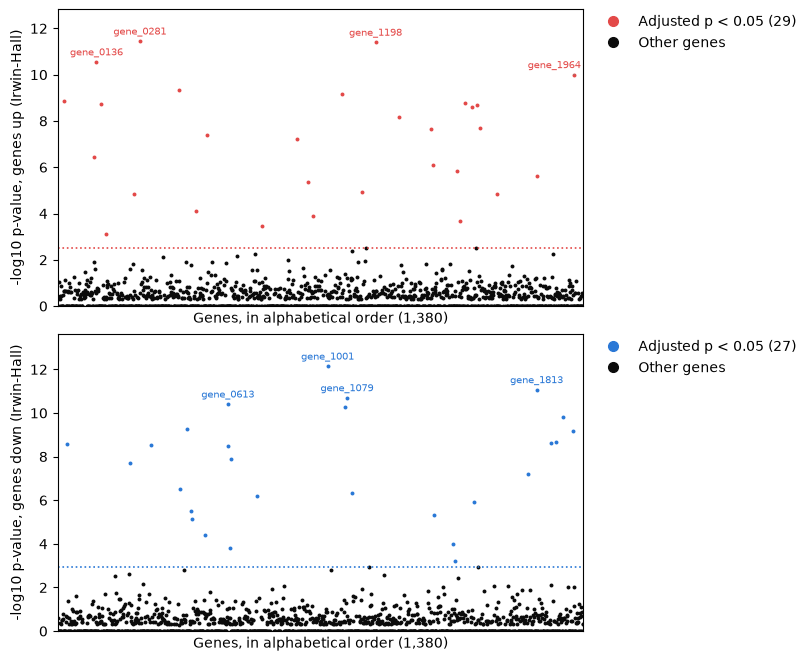

In [2]:
ranks = sumrank(studies, monocytes, contrast)
table = ranks.features
print(f"{len(table):,} genes ranked, by all six cohorts")
row("adjusted p < 0.05", columns)
for direction in ("up", "down"):
    adjusted = table[f"{direction}_adjusted_p_value"]
    row(f"genes {direction}", by_truth(table["feature_id"], adjusted))
figure, axes = plt.subplots(2, 1, figsize=(8, 6.5), layout="constrained")
plot_sumrank(ranks, top=4, ax=axes[0])
plot_sumrank(ranks, direction="down", top=4, ax=axes[1])
plt.show()

SumRank finds 56 genes, 29 up and 27 down, all but one changed in every cohort, and no
gene of a single cohort, which ranks high in that cohort only. It ranks the 1,380
genes that all six cohorts tested: genes that cohort_3 or cohort_5 did not measure,
or that the expression filter of the small cohort_5 left out, are not ranked.

## Summing the best ranks

A cohort can miss a change for reasons of its own, so SumRank can sum each gene's best
ranks only, those of the cohorts that rank it highest, as the paper did where a disease
had many studies. A sum of the best ranks is smaller than a sum of uniform ranks, so
its Irwin-Hall p-values are too small, as {api}`sumrank` warns, and its p-values come
from permutations instead: the case and control labels are permuted within each
cohort, each cohort's analysis is run again, and the statistics of every gene in every
permutation make one null distribution. Here the best 4 of the 6 cohorts are summed
(`n_studies_summed=4`), with 30 permutations.

In [3]:
with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    irwin_hall = sumrank(studies, monocytes, contrast, n_studies_summed=4)
print(textwrap.fill(f"RuntimeWarning: {caught[0].message}", 78), end="\n\n")
permuted = sumrank(
    studies, monocytes, contrast, n_studies_summed=4, n_permutations=30, rng=1
)
row("up or down, adjusted p < 0.05", columns)
for name, found_by in (
    ("all 6 cohorts, Irwin-Hall", ranks),
    ("best 4, Irwin-Hall", irwin_hall),
    ("best 4, 30 permutations", permuted),
):
    table = found_by.features
    up, down = table["up_adjusted_p_value"], table["down_adjusted_p_value"]
    row(name, by_truth(table["feature_id"], np.minimum(up, down)))

ranks are too small, as the sum of the best ranks is smaller than a sum of
uniform ranks; the p_value columns hold them, so take p-values from
permutations (n_permutations and permute)



up or down, adjusted p < 0.05        every cohort  one cohort  unchanged
all 6 cohorts, Irwin-Hall                      55           0          1
best 4, Irwin-Hall                             62           7         16
best 4, 30 permutations                        59           0          0


Summed over the best 4 of the 6 cohorts, the Irwin-Hall p-values find 16 unchanged
genes and 7 of single cohorts, as the warning says they would. With permutations, the
same statistics find 59 genes, all changed in every cohort, more than the sum over all
six.

## Prediction in held-out cohorts

Genes that replicate should tell cases from controls in a cohort that had no part in
choosing them. {api}`held_out_prediction` leaves each cohort out in turn, chooses 20
genes up and 20 down in every cell type from the other five, by SumRank and by a
random-effects meta-analysis, as the paper compares them, scores every donor of the
held-out cohort by how high its profiles rank those genes, and reports the area under
the ROC curve (AUC) of its cases against its controls ([Prediction in held-out
studies](../statistics/replication.md#held-out-prediction)). {api}`plot_held_out_auc`
draws it for every cohort. The paper chose the proportion of studies summed by
cross-validation; the mean AUC for a few proportions comes first.

proportion of the cohorts summed: mean AUC
  1.0: SumRank 0.92, meta-analysis 0.87
  0.8: SumRank 0.89, meta-analysis 0.87
  0.6: SumRank 0.87, meta-analysis 0.87
  0.4: SumRank 0.92, meta-analysis 0.87


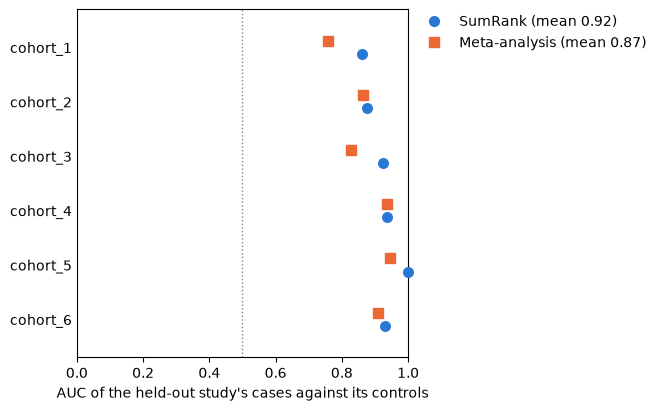

In [4]:
lines = ["proportion of the cohorts summed: mean AUC"]
for proportion in (1.0, 0.8, 0.6, 0.4):
    auc = held_out_prediction(
        studies, contrast, n_features=20, proportion_of_studies=proportion
    ).auc
    sumrank_auc = np.nanmean(auc.filter(method="sumrank")["auc"])
    meta_auc = np.nanmean(auc.filter(method="meta_analysis")["auc"])
    line = f"SumRank {sumrank_auc:.2f}, meta-analysis {meta_auc:.2f}"
    lines.append(f"  {proportion}: {line}")
print("\n".join(lines))
prediction = held_out_prediction(studies, contrast, n_features=20)
plot_held_out_auc(prediction)
plt.show()

SumRank's genes predict the held-out cases a little better here, with a mean AUC of
0.92 against 0.87, most clearly in cohort_1 and cohort_3; with six cohorts, the
proportion summed moves the mean AUC between 0.87 and 0.92 only. In the 17 studies of
Alzheimer's disease of the paper, SumRank's genes predicted the left-out datasets with
a mean AUC of 0.78, as did those of the datasets merged into one model with the
dataset as a covariate; those of the paper's inverse-variance meta-analysis, a
random-effects model, 0.74, and the genes of single datasets 0.67 (its Table 1)
[@nakatsuka2025].

## Choices

- **Which genes replicate.** {api}`sumrank` by default, which asks that a gene rank
  high in study after study and weighs every cohort alike; {api}`partial_conjunction`
  to claim a change in at least u cohorts, with a false discovery rate over the genes;
  a meta-analysis to estimate each gene's change with its uncertainty ([Defaults and
  choices](../statistics/replication.md#replication-defaults)). {api}`replication`
  gives the partial conjunctions with the tables below: the genes found in each number
  of cohorts and the agreement between pairs of cohorts.
- **SumRank's proportion and p-values.** Summing every cohort, the Irwin-Hall p-values
  serve; summing fewer (`n_studies_summed`, or `proportion_of_studies`) needs
  permutations (`n_permutations`), of the labels of the factor that the contrast
  compares, or of the variable `permute` names. Each permutation runs every cohort's
  analysis again, and designs with random effects cannot be permuted. SumRank ranks
  only the genes that every cohort tested, so a cohort with a short panel of genes or
  a strict expression filter shortens the list for all.
- **Which combination of p-values.** Fisher's method finds genes that any cohort
  changes; Stouffer's, weighted by the square roots of the cohorts' sizes, the default
  of {api}`replication`, rewards evidence the cohorts share; neither says that a change
  replicates, which {api}`partial_conjunction` tests (`at_least`, and
  `conjunction_method` for Simes's, Fisher's or Stouffer's combination), as below.
- **π₁ on few genes.** π₀ is estimated at λ = 0.5, which few genes allow;
  `null_proportion` chooses qvalue's smoother (`{}`) or its bootstrap
  (`{"method": "bootstrap"}`) instead, for cohorts that find many genes ([How well one
  study replicates another](../statistics/replication.md#pi1-between-studies)).
- **Held-out prediction.** `n_features` sets how many genes up and down are chosen in
  each cell type, and `groups` the cell types scored.

### Genes found in k cohorts

{api}`replication` reads one cell type and contrast of every cohort, lined up gene by
gene, and counts the cohorts that find each gene (adjusted p-value below 0.05) and in
which direction. {api}`plot_replicated_genes` draws how many genes each number of
cohorts finds, as the paper that introduced SumRank counts them [@nakatsuka2025].

monocyte genes found: 133
  by one cohort only: 73
    changed in every cohort: 22
    changed in that cohort alone: 43
    unchanged: 8


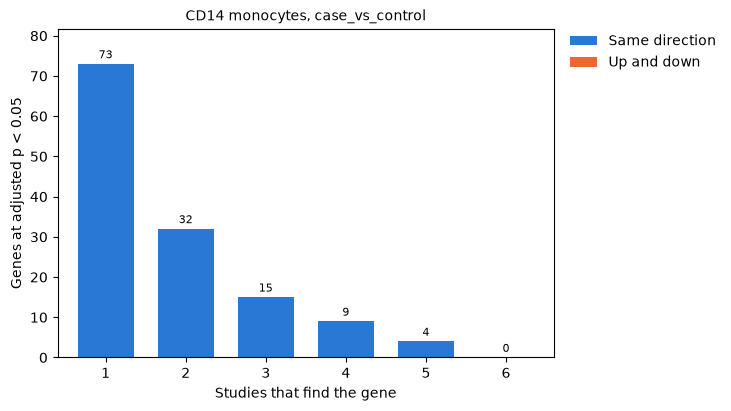

In [5]:
replicated = replication(studies, monocytes, contrast)
found = replicated.features
once = found.filter(n_found=1)["feature_id"]
every, own, none = (np.isin(once, kind).sum() for kind in truth_sets)
print(f"monocyte genes found: {np.count_nonzero(found['n_found'])}")
print(f"  by one cohort only: {once.size}")
print(f"    changed in every cohort: {every}")
print(f"    changed in that cohort alone: {own}")
print(f"    unchanged: {none}")
plot_replicated_genes(replicated)
plt.show()

Most genes are found by one cohort only, 73 of the 133 found, and none by all six. Of
those 73, 43 belong to that cohort alone, but 22 change in every cohort and the other
cohorts missed them: a gene that one cohort finds and the next does not is not
necessarily a change of one cohort.

### How well each cohort replicates the others

π₁ of the second cohort's p-values for the genes the first finds estimates the share
of them that change in the second cohort, whether it finds them or not ([How well one
study replicates another](../statistics/replication.md#pi1-between-studies)).
{api}`plot_study_agreement` draws it for every pair of cohorts. Each entry is computed
from the few dozen genes that one cohort finds; on so few p-values qvalue's default
estimate of π₀, a smoother read at λ = 0.95, is unsteady, so the analysis estimates it
at a single λ of 0.5, which is steadier; `null_proportion={}` asks for qvalue's
smoother.

pi1 by qvalue's smoother: 0.00 to 1.00, mean 0.72
pi1 by lambda 0.5: 0.47 to 1.00, mean 0.73
share of the genes found by both cohorts: mean 0.32
share with the same sign: 0.73 to 1.00


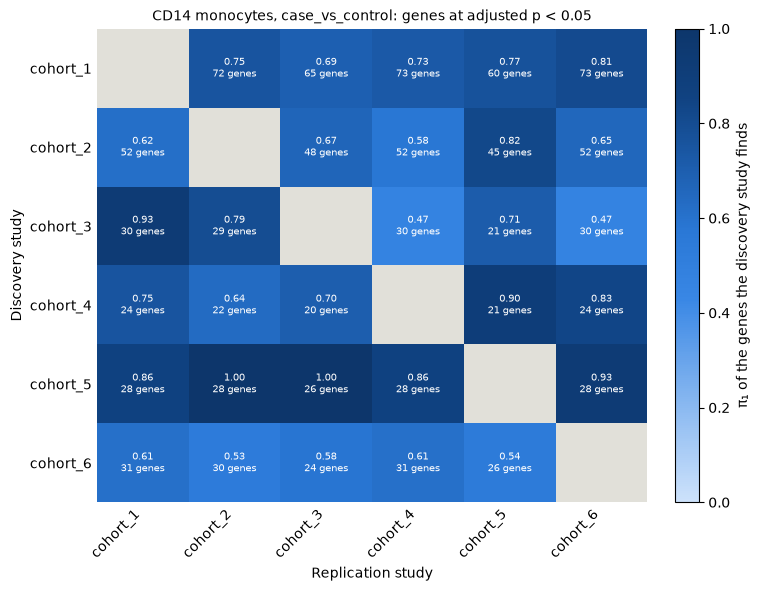

In [6]:
smoother = replication(studies, monocytes, contrast, null_proportion={})
pairs = replicated.study_pairs
for name, pi1 in (
    ("qvalue's smoother", smoother.study_pairs["pi1"]),
    ("lambda 0.5", pairs["pi1"]),
):
    low, high, mean = pi1.min(), pi1.max(), pi1.mean()
    print(f"pi1 by {name}: {low:.2f} to {high:.2f}, mean {mean:.2f}")
both = pairs["n_features_found_in_both"] / pairs["n_features_found"]
signs = pairs["sign_agreement"]
print(f"share of the genes found by both cohorts: mean {both.mean():.2f}")
print(f"share with the same sign: {signs.min():.2f} to {signs.max():.2f}")
figure, ax = plt.subplots(figsize=(7.5, 5.8), layout="constrained")
plot_study_agreement(replicated, ax=ax)
plt.show()

π₁ lies between 0.47 and 1.00, 0.73 on average: of the genes one cohort finds, most
change in each other cohort, although the other cohort finds only a third of them
itself, on average, and their signs agree for 73% to 100% of them. qvalue's smoother
gave π₁ from 0 to 1 on the same genes. π₁ is not symmetric: it reads the genes of the
discovery cohort in the p-values of the replication cohort, and the genes of the small
cohort_5, its clearest changes, replicate best.

### Combined p-values and replicated changes

{api}`combine_p_values` combines each gene's p-values over the cohorts that tested it
into the p-value of the hypothesis that no cohort changes it, by Fisher's method, which
responds to the strongest cohort, or by Stouffer's, weighted by the square roots of the
cohorts' sizes, which responds to the evidence they share ([Combined
p-values](../statistics/replication.md#combined-p-values)); the replication result
holds the latter. A small combined p-value says that some cohort changes the gene, not
that the change replicates. {api}`partial_conjunction` tests instead whether at least u
cohorts change it, in one direction ([An effect in at least u
studies](../statistics/replication.md#partial-conjunction)); the replication result
holds it for u = 2. Both take the p-values of every cohort as
{api}`StudyResults.matrix` lines them up, cohorts x genes, with NaN where a cohort did
not test a gene. The monocyte genes each finds at a false discovery rate of 5%, with
the random-effects meta-analysis (REML) of [Align and combine studies](combine_studies.ipynb)
for comparison:

In [7]:
p_values = studies.matrix("p_value", monocytes, contrast)
log2_fc = studies.matrix("log2_fold_change", monocytes, contrast)
ids, found_ids = collection.features["feature_id"], found["feature_id"]
fisher = combine_p_values(p_values, method="fisher", directions=log2_fc)
in_three = partial_conjunction(p_values, 3, directions=log2_fc)
meta = meta_analysis(studies).table(monocytes, contrast)
methods = {
    "Fisher": (ids, adjust_p_values(fisher.p_value, "bh")),
    "Stouffer, weighted": (found_ids, found["adjusted_p_value"]),
    "in at least 2 cohorts": (found_ids, found["replication_adjusted_p_value"]),
    "in at least 3 cohorts": (ids, adjust_p_values(in_three.p_value, "bh")),
    "meta-analysis (REML)": (meta["feature_id"], meta["adjusted_p_value"]),
}
row("genes at adjusted p < 0.05", columns)
for name, (feature_ids, adjusted) in methods.items():
    row(name, by_truth(feature_ids, adjusted))

genes at adjusted p < 0.05           every cohort  one cohort  unchanged
Fisher                                         94          36          3
Stouffer, weighted                             93          19          2
in at least 2 cohorts                          41           0          0
in at least 3 cohorts                           7           0          0
meta-analysis (REML)                           80           0          2


Fisher's method finds 94 of the 100 genes changed in every cohort, and 36 of the 60
genes of single cohorts: one cohort's strong change is enough. Stouffer's method,
which weighs the evidence of every cohort and its direction, keeps 19 of those. The
partial conjunction tests find no gene of a single cohort, at a cost in power: 41
genes in at least 2 cohorts and 7 in at least 3, since the change must be clear in
that many cohorts on its own. The random-effects meta-analysis finds 80, none of a
single cohort.